<h1><center>Трансформеры</h1></center>

<text>Наиболее доминантная модель нейронной сети. Передовая. Благодаря удержанию внимания и т.д. Перве представление, это трансформеры типа энкодер-декодер</text>

<h2>Предобработка данных<h2>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm
import torch


plt.rcParams.update({'font.size': 14})
sns.set_style('whitegrid')
torch.set_printoptions(threshold=float('inf'))


In [4]:
# !pip3 install torch==2.2.0
# !pip3 install torchtext==0.17.0

In [5]:
# !pip3 install portalocker==2.8.2

In [6]:
from torchtext.datasets import IMDB


def get_dataset(split='train'):
    dataset = IMDB('./data', split=split)
    texts, targets = [], []
    for label, text in dataset:
        targets += [label - 1]
        texts += [text]
    return pd.DataFrame({'raw_text': texts, 'target': targets})


train_set = get_dataset('train')
test_set = get_dataset('test')
train_set.shape, test_set.shape


((25000, 2), (25000, 2))

In [7]:
train_set.iloc[1]['raw_text']

'"I Am Curious: Yellow" is a risible and pretentious steaming pile. It doesn\'t matter what one\'s political views are because this film can hardly be taken seriously on any level. As for the claim that frontal male nudity is an automatic NC-17, that isn\'t true. I\'ve seen R-rated films with male nudity. Granted, they only offer some fleeting views, but where are the R-rated films with gaping vulvas and flapping labia? Nowhere, because they don\'t exist. The same goes for those crappy cable shows: schlongs swinging in the breeze but not a clitoris in sight. And those pretentious indie movies like The Brown Bunny, in which we\'re treated to the site of Vincent Gallo\'s throbbing johnson, but not a trace of pink visible on Chloe Sevigny. Before crying (or implying) "double-standard" in matters of nudity, the mentally obtuse should take into account one unavoidably obvious anatomical difference between men and women: there are no genitals on display when actresses appears nude, and the s

In [8]:
test_set.iloc[1]['raw_text']

"Worth the entertainment value of a rental, especially if you like action movies. This one features the usual car chases, fights with the great Van Damme kick style, shooting battles with the 40 shell load shotgun, and even terrorist style bombs. All of this is entertaining and competently handled but there is nothing that really blows you away if you've seen your share before.<br /><br />The plot is made interesting by the inclusion of a rabbit, which is clever but hardly profound. Many of the characters are heavily stereotyped -- the angry veterans, the terrified illegal aliens, the crooked cops, the indifferent feds, the bitchy tough lady station head, the crooked politician, the fat federale who looks like he was typecast as the Mexican in a Hollywood movie from the 1940s. All passably acted but again nothing special.<br /><br />I thought the main villains were pretty well done and fairly well acted. By the end of the movie you certainly knew who the good guys were and weren't. The

In [9]:
train_set['target'].value_counts()

target
0    12500
1    12500
Name: count, dtype: int64

In [10]:
test_set['target'].value_counts()

target
0    12500
1    12500
Name: count, dtype: int64

Сеты идеально сбалансированны

In [11]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer


nltk.download('omw-1.4')
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('stopwords')


stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\nuyki\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\nuyki\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\nuyki\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\nuyki\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\nuyki\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [12]:
def preprocess(text):
    text = list(filter(str.isalpha, word_tokenize(text.lower())))
    text = list(lemmatizer.lemmatize(word) for word in text)
    text = list(word for word in text if word not in stop_words)
    return ' '.join(text)

train_set['text'] = train_set.apply(lambda row: preprocess(row.raw_text), axis=1)
test_set['text'] = test_set.apply(lambda row: preprocess(row.raw_text), axis=1)

In [13]:
print(f'Train:\n{train_set.iloc[1]["text"]}')
print(f'Test:\n{test_set.iloc[1]["text"]}')

Train:
curious yellow risible pretentious steaming pile doe matter one political view film hardly taken seriously level claim frontal male nudity automatic true seen film male nudity granted offer fleeting view film gaping vulva flapping labium nowhere exist go crappy cable show schlongs swinging breeze clitoris sight pretentious indie movie like brown bunny treated site vincent gallo throbbing johnson trace pink visible chloe sevigny cry implying matter nudity mentally obtuse take account one unavoidably obvious anatomical difference men woman genitals display actress appears nude said man fact generally wo see female genitals american film anything short porn explicit erotica alleged less double standard admittedly depressing ability come term culturally inside woman body
Test:
worth entertainment value rental especially like action movie one feature usual car chase fight great van damme kick style shooting battle shell load shotgun even terrorist style bomb entertaining competently 

<h2>Baseline</h2>

— простая базовая модель или алгоритм, который создают в самом начале проекта. Он служит точкой отсчета и минимальным стандартом качества. Все будущие, более сложные модели сравнивают с этим эталоном, чтобы понять, имеют ли смысл усложнения.

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score


tf_idf = TfidfVectorizer().fit(train_set['text'])
train_idf = tf_idf.transform(train_set['text'])
test_idf = tf_idf.transform(test_set['text'])

log_reg = LogisticRegression(n_jobs=-1).fit(train_idf, train_set['target'])

d:\MIREA\DPO\.venv3_11_8\Lib\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


In [15]:
print(f'Train acc: {accuracy_score(train_set["target"], log_reg.predict(train_idf)):.4f}') 
print(f'Test acc: {accuracy_score(test_set["target"], log_reg.predict(test_idf)):.4f}') 
print(f'Number params: {log_reg.coef_.shape}')

Train acc: 0.9322
Test acc: 0.8789
Number params: (1, 63885)


<h2>Токенизация данных</h2>

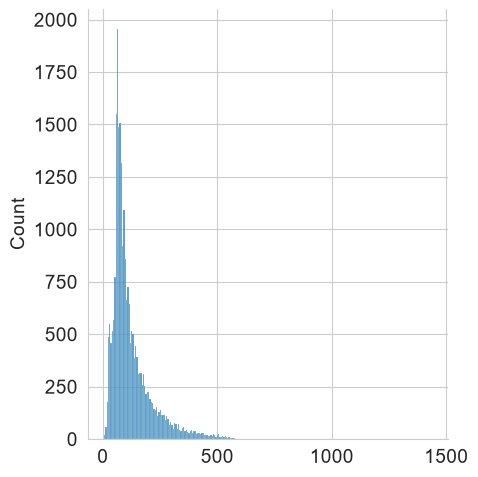

In [16]:
from torchtext.vocab import build_vocab_from_iterator


def dataset_iterator(texts):
    for text in texts:
        yield text.split()


vocab = build_vocab_from_iterator(
    dataset_iterator(train_set['text']),
    specials=['<pad>', '<unk>'], min_freq=10
    )

train_tokens = []
for text in dataset_iterator(train_set['text']):
    tokens = [vocab[word] if word in vocab else vocab['<unk>'] for word in text]
    train_tokens += [tokens]

test_tokens = []
for text in dataset_iterator(test_set['text']):
    tokens = [vocab[word] if word in vocab else vocab['<unk>'] for word in text]
    test_tokens += [tokens]

lengths = np.array([len(tokens) for tokens in train_tokens])
sns.displot(lengths)
plt.show()

In [17]:
max_length = 128

tokenized_train = torch.full((len(train_tokens), max_length), vocab['<pad>'], dtype=torch.int32)
for i, tokens in enumerate(train_tokens):
    length = min(max_length, len(tokens))
    tokenized_train[i, :length] = torch.tensor(tokens[:length])

tokenized_test = torch.full((len(test_tokens), max_length), vocab['<pad>'], dtype=torch.int32)
for i, tokens in enumerate(test_tokens):
    length = min(max_length, len(tokens))
    tokenized_test[i, :length] = torch.tensor(tokens[:length])

In [18]:
targets_train = torch.tensor(train_set['target'], dtype=torch.int32)
targets_test = torch.tensor(test_set['target'], dtype=torch.int32)

In [19]:
from torch.utils.data import TensorDataset, DataLoader


train_dataset = TensorDataset(tokenized_train, targets_train)
test_dataset = TensorDataset(tokenized_test, targets_test)

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size, shuffle=True, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size, shuffle=False, pin_memory=True)

In [20]:
train_dataset[0]


(tensor([ 1380,   261,   873,  5832,  2967,     3,    28,   508,    25,   429,
            28,     3, 17065,  6078,    52,   640,  2241,   458,  1389,   113,
             5,   989,  2727,    18,    17,     2,     2,    43,  5203,    96,
            94,  3421,   328,   667,   619,  3815,    61,   682,   182,    34,
           666,    61,   717,   543,   155,   268,   464,   713,     1,    98,
           632,   840,   714,  2395,   199,  1202,   714,  2100,   596,  1940,
          3371,  1732, 14433,     1,   463,  2131,     8,   285,   328,  1233,
          5910,   847,     2,     2,   250,    50,   474,     3,   989,  7278,
            18,   285,   843,    20,   138,    14,   135,     7,  5826,    32,
          4014, 15758,   218,    60,  1421,   480,   285,   843,   516,  7422,
          3421,   315,    14, 12413,  3870,  4058,   910,    10,    80,   210,
           193,  1508,   285,    20,     2,     2, 10848,   547,    90,   285,
           483,     5,   483,  1399,   958,   143,  

<h2>Архитектура Трансформеров</h2>

In [21]:
import math
from torch import nn


class PosititonalEncoder(nn.Module):
    def __init__(self, max_length, embed_dim, dropout):
        super().__init__()
        self.pos_features = torch.zeros(max_length, embed_dim)
        positions = torch.arange(0, max_length, dtype=torch.float).unsqueeze(1)
        freqs = torch.exp(torch.arange(0, embed_dim, 2, dtype=torch.float) * (-math.log(10000) / embed_dim)).unsqueeze(0)
        
        print(freqs)

        arguments = positions * freqs
        self.pos_features[:, 0::2] = torch.sin(arguments)
        self.pos_features[:, 1::2] = torch.cos(arguments)
        self.pos_features = self.pos_features.unsqueeze(0)
        self.pos_features = nn.Parameter(self.pos_features, requires_grad=False)
        # Сначала, вообще не обучали параметры, а использовали стандратные значения,
        # Мы делаем также для экономии обучаемых параметров

        self.dropout = nn.Dropout(dropout)
    
    def forward(self, inputs):
        outputs = inputs + self.pos_features[:, :inputs.shape[1]]
        return self.dropout(outputs)

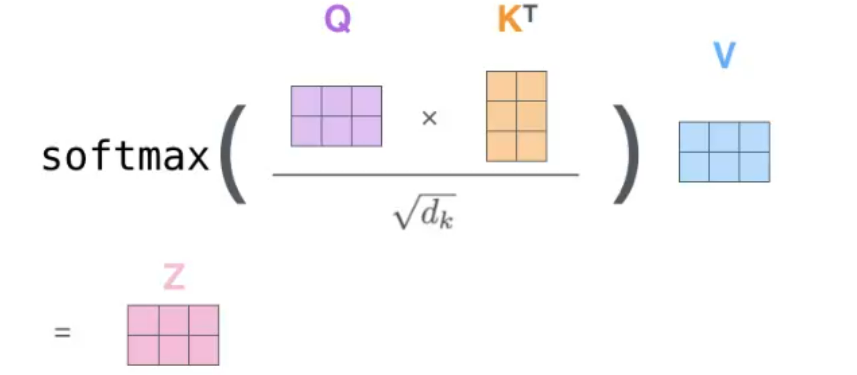

In [22]:
class Attention(nn.Module):
    def __init__(self, embed_dim, num_heads, dropout):
        super().__init__()
        attention_dim = embed_dim // num_heads

        self.WQ = nn.Linear(embed_dim, attention_dim, bias=False)
        self.WK = nn.Linear(embed_dim, attention_dim, bias=False)
        self.WV = nn.Linear(embed_dim, attention_dim, bias=False)

        self.dropout = nn.Dropout(dropout)

    def forward(self, query, key, value, mask=None):
        Q = self.WQ(query)
        K = self.WK(key)
        V = self.WV(value)

        norm_factor = math.sqrt(Q.shape[-1])    
        dot_products = torch.bmm(Q, K.transpose(1, 2)) / norm_factor

        if mask is not None:
            dot_products = dot_products.masked_fill(mask, -math.inf)
        
        attention_score = nn.functional.softmax(dot_products, dim=-1)
        attention = torch.bmm(self.dropout(attention_score), V)
        return attention, attention_score
    
class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim, num_heads, dropout):
        super(MultiHeadAttention, self).__init__()
        assert embed_dim % num_heads == 0
        self.attention_heads = nn.ModuleList([Attention(embed_dim, num_heads,
                                                        dropout) for _ in range(num_heads)])
        self.linear = nn.Linear(embed_dim, embed_dim, bias=False)
        self.dropout = nn.Dropout(dropout)

    def forward(self, query, key, value, mask=None):
        attentions, attention_scores = [], []

        for head in self.attention_heads:
            attention, attention_score = head(query, key, value, mask)
            attentions += [attention]
            attention_scores += [attention_score]
        
        attentions = torch.cat(attentions, dim=-1)
        attention_scores = torch.stack(attention_scores, dim=-1)

        outputs = self.linear(attentions)
        outputs = self.dropout(outputs)

        return outputs, attention_scores
    

In [23]:
def create_padding_mask(tokens, pad_idx=vocab['<pad>']):
    length = tokens.shape[-1]
    padding_mask = (tokens == pad_idx)
    padding_mask = padding_mask.unsqueeze(1).repeat(1, length, 1)
    return padding_mask

In [24]:
class TransformerLayer(nn.Module):
    def __init__(self, embed_dim, fc_dim, num_heads, dropout):
        super().__init__()
        self.self_attention = MultiHeadAttention(embed_dim, num_heads, dropout)
        self.feedforward = nn.Sequential(nn.Linear(embed_dim, fc_dim),
                                         nn.GELU(),
                                         nn.Dropout(dropout),
                                         nn.Linear(fc_dim, embed_dim),
                                         nn.Dropout(dropout))
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)
    
    def forward(self, inputs, mask):
        attention, attention_score = self.self_attention(query=self.norm1(inputs),
                                                         key=self.norm1(inputs),
                                                         value=self.norm1(inputs),
                                                         mask=mask)
        outputs = inputs + attention
        outputs = outputs + self.feedforward(self.norm2(outputs))
        return outputs, attention_score
    
class Transformer(nn.Module):
    def __init__(self, vocab_size, max_length, num_classes, embed_dim,
                 fc_dim, num_heads, num_layers, dropout):
        super().__init__()
        self.embed_dim = embed_dim
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.pos_encoder = PosititonalEncoder(max_length, embed_dim, dropout)
        self.layers = nn.ModuleList([TransformerLayer(embed_dim, fc_dim, num_heads, dropout) for _ in range(num_layers)])
        self.classifier = nn.Linear(embed_dim, num_classes)

    def forward(self, tokens):
        embeds = self.embedding(tokens) * math.sqrt(self.embed_dim)
        outputs = self.pos_encoder(embeds)

        padding_mask = create_padding_mask(tokens)
        attention_scores = []
        for layer in self.layers:
            outputs, attention_score = layer(outputs, padding_mask)
            attention_scores += [attention_score]
        attention_scores = torch.stack(attention_scores, dim=-1)

        mask = (tokens != vocab['<pad>']).to(torch.float).detach()
        lengths = mask.sum(dim=-1).detach()
        outputs = (outputs * mask.unsqueeze(2)).sum(dim=1) / lengths.unsqueeze(1)
        logits = self.classifier(outputs)
        return logits, attention_scores
    

In [30]:
from IPython.display import clear_output


def plot_losses(train_losses, test_losses, train_accuracies, test_accuracies):
    clear_output()
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(range(1, len(train_losses) + 1), train_losses, label='train')
    axes[0].plot(range(1, len(test_losses) + 1), test_losses, label='test')
    axes[0].set_ylabel('loss')

    axes[1].plot(range(1, len(train_accuracies) + 1), train_accuracies, label='train')
    axes[1].plot(range(1, len(test_accuracies) + 1), test_accuracies, label='test')
    axes[1].set_ylabel('accuracy')

    for ax in axes:
        ax.set_xlabel('epoch')
        ax.legend()

    plt.show()

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = Transformer(vocab_size=len(vocab), max_length=max_length, num_classes=1,
                    embed_dim=64, fc_dim=64, num_heads=4, num_layers=4, dropout=.2).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=3e-4)
criterion = nn.BCELoss()
print('Num of parameters:', sum(p.numel() for p in model.parameters())) 
print('Num of parameters requires grad:', sum(p.numel() for p in model.parameters() if p.requires_grad)) 

tensor([[1.0000e+00, 7.4989e-01, 5.6234e-01, 4.2170e-01, 3.1623e-01, 2.3714e-01,
         1.7783e-01, 1.3335e-01, 1.0000e-01, 7.4989e-02, 5.6234e-02, 4.2170e-02,
         3.1623e-02, 2.3714e-02, 1.7783e-02, 1.3335e-02, 1.0000e-02, 7.4989e-03,
         5.6234e-03, 4.2170e-03, 3.1623e-03, 2.3714e-03, 1.7783e-03, 1.3335e-03,
         1.0000e-03, 7.4989e-04, 5.6234e-04, 4.2170e-04, 3.1623e-04, 2.3714e-04,
         1.7783e-04, 1.3335e-04]])


[transformers] Disabling PyTorch because PyTorch >= 2.4 is required but found 2.2.0+cu121
[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


Num of parameters: 1214401
Num of parameters requires grad: 1206209


<h2>Обучение модели

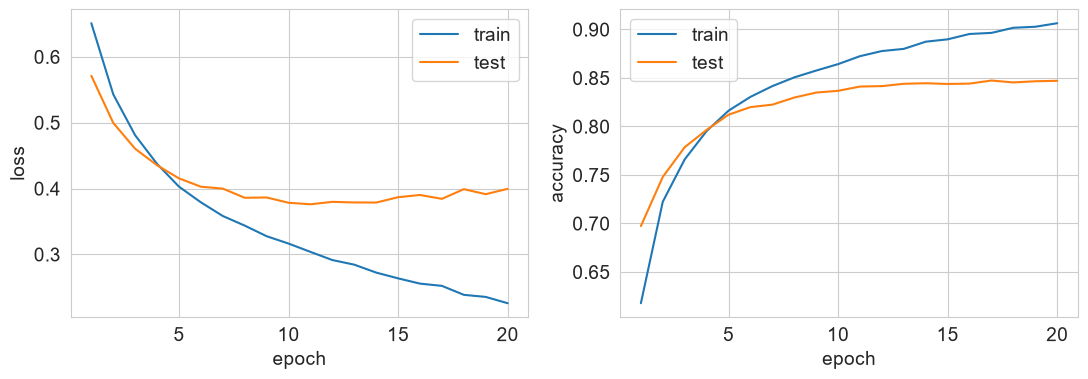

Best test accuracy: 0.84736


In [24]:
def train_model(model, optimizer, criterion, train_loader, test_loader, num_epochs):
    train_losses, test_losses = [], []
    train_acc, test_acc = [], []
    for epoch in range(1, num_epochs + 1):
        model.train()
        running_loss, running_acc = 0.0, 0.0
        for tokens, labels in tqdm(train_loader, desc=f'Training {epoch:2d}/{num_epochs:2d}'):
            optimizer.zero_grad()
            tokens, labels = tokens.to(device), labels.to(device)
            logits, _ = model(tokens)
            probs = torch.sigmoid(logits.squeeze(1))
            loss = criterion(probs, labels.to(torch.float))
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * tokens.shape[0]
            running_acc += ((probs > .5).to(torch.int) == labels).sum().item()

        train_losses += [running_loss / len(train_loader.dataset)]
        train_acc += [running_acc / len(train_loader.dataset)]

        model.eval()
        running_loss, running_acc = 0.0, 0.0
        for tokens, labels in tqdm(test_loader, desc=f'Testing {epoch:2d}/{num_epochs:2d}'):
            tokens, labels = tokens.to(device), labels.to(device)
            with torch.inference_mode():
                logits, _ = model(tokens)
                probs = torch.sigmoid(logits.squeeze(1))
                loss = criterion(probs, labels.to(torch.float))

            running_loss += loss.item() * tokens.shape[0]
            running_acc += ((probs > .5).to(torch.int) == labels).sum().item()

        test_losses += [running_loss / len(test_loader.dataset)]
        test_acc += [running_acc / len(test_loader.dataset)]
        plot_losses(train_losses, test_losses, train_acc, test_acc)
    return train_losses, test_losses, train_acc, test_acc


num_epochs = 20
train_losses, test_losses, train_acc, test_acc = train_model(model, optimizer,criterion,
                                                             train_loader, test_loader, num_epochs)

print(f'Best test accuracy: {max(test_acc)}')

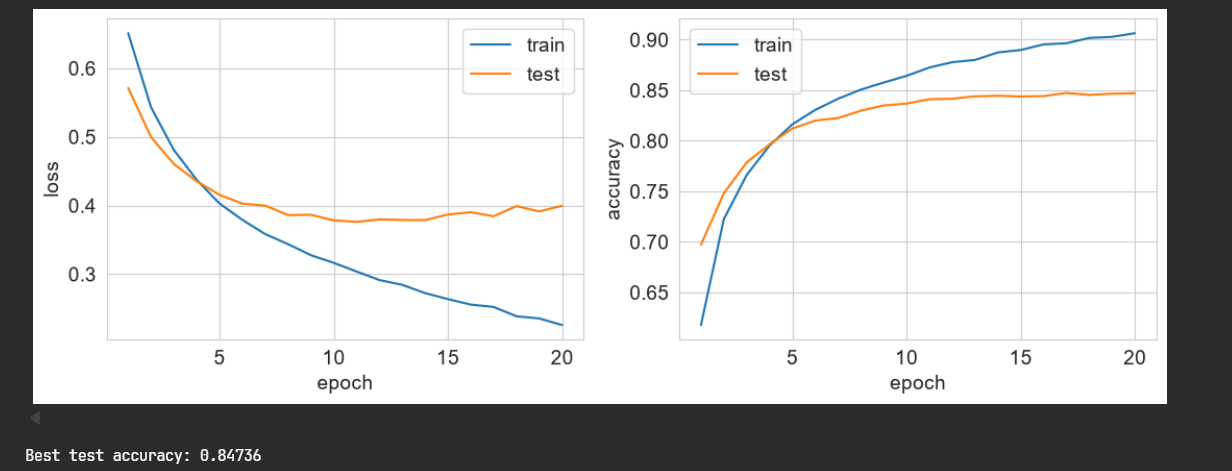

<h1><center>Практическое задание</h1></center>

1. Разобраться в архитектуре и самостоятельно реализовать декодер

In [26]:
def create_key_padding_mask(tokens, query_length, pad_idx=vocab['<pad>']):
    batch_size, key_length = tokens.shape
    padding_mask = (tokens == pad_idx)
    padding_mask = padding_mask.unsqueeze(1)
    padding_mask = padding_mask.expand(batch_size, query_length, key_length)
    return padding_mask

def create_encoder_self_attention_mask(src_tokens, pad_idx=vocab['<pad>']):
    src_length = src_tokens.shape[1]
    return create_key_padding_mask(src_tokens, src_length, pad_idx)

def create_causal_mask(length, device):
    mask = torch.triu(
        torch.ones(length, length, dtype=torch.bool, device=device),
        diagonal = 1
    )
    return mask.unsqueeze(0)

def create_decoder_self_attention_mask(tgt_tokens, pad_idx=vocab['<pad>']):
    target_length = tgt_tokens.shape[1]
    device = tgt_tokens.device
    
    padding_mask = create_key_padding_mask(tgt_tokens, target_length, pad_idx)
    causal_mask = create_causal_mask(tgt_tokens, device)
    result_mask = padding_mask | causal_mask
    return result_mask

def create_cross_attention_mask(src_tokens, tgt_length, src_pad_idx=vocab['<pad>']):
    return create_key_padding_mask(src_tokens, tgt_length, src_pad_idx)

In [28]:
class TransformerEncoderLayer(nn.Module):
    def __init__(self, embed_dim, fc_dim, num_heads, dropout):
        super().__init__()
        self.self_attention = MultiHeadAttention(embed_dim, num_heads, dropout)
        self.feedforward = nn.Sequential(nn.Linear(embed_dim, fc_dim),
                                         nn.GELU(),
                                         nn.Dropout(dropout),
                                         nn.Linear(fc_dim, embed_dim),
                                         nn.Dropout(dropout))
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)
    
    def forward(self, inputs, mask):
        x = self.norm1(inputs)
        attention, attention_score = self.self_attention(query=x,
                                                         key=x,
                                                         value=x,
                                                         mask=mask)
        outputs = inputs + attention
        outputs = outputs + self.feedforward(self.norm2(outputs))
        return outputs, attention_score

class TransformerEncoderPart(nn.Module):
    def __init__(self, vocab_size, max_length, embed_dim, fc_dim,
                 num_heads, num_layers, dropout, pad_idx):
        super().__init__()
        self.embed_dim = embed_dim
        self.pad_idx = pad_idx
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.pos_encoder = PosititonalEncoder(max_length, embed_dim, dropout)
        self.layers = nn.ModuleList([TransformerEncoderLayer(embed_dim, fc_dim, num_heads, dropout) for _ in range(num_layers)])

    def forward(self, tokens):
        embeds = self.embedding(tokens) * math.sqrt(self.embed_dim)
        outputs = self.pos_encoder(embeds)

        padding_mask = create_encoder_self_attention_mask(tokens, self.pad_idx)
        attention_scores = []
        for layer in self.layers:
            outputs, attention_score = layer(outputs, padding_mask)
            attention_scores += [attention_score]
        attention_scores = torch.stack(attention_scores, dim=-1)
        return outputs, attention_scores

class TransformerDecoderLayer(nn.Module):
    def __init__(self, embed_dim, fc_dim, num_heads, dropout):
        super().__init__()
        self.self_attention = MultiHeadAttention(embed_dim, num_heads, dropout)
        self.cross_attention = MultiHeadAttention(embed_dim, num_heads, dropout)
        self.feedforward = nn.Sequential(nn.Linear(embed_dim, fc_dim),
                                         nn.GELU(),
                                         nn.Dropout(dropout),
                                         nn.Linear(fc_dim, embed_dim),
                                         nn.Dropout(dropout))
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.norm3 = nn.LayerNorm(embed_dim)
    
    def forward(self, inputs, self_attention_mask, cross_attention_mask, encoder_outputs):
        x = self.norm1(inputs)
        self_attention_outputs, self_attention_score = self.self_attention(query=x,
                                                                   key=x,
                                                                   value=x,
                                                                   mask=self_attention_mask)
        outputs = inputs + self_attention_outputs

        x = self.norm2(outputs)
        cross_attention_outputs, cross_attention_score = self.cross_attention(query=x,
                                                                              key=encoder_outputs,
                                                                              value=encoder_outputs,
                                                                              mask=cross_attention_mask)
        
        outputs = outputs + cross_attention_outputs

        outputs = outputs + self.feedforward(self.norm3(outputs))
        return outputs, self_attention_score, cross_attention_score

class TransformerDecoderPart(nn.Module):
    def __init__(self, vocab_size, max_length, embed_dim, fc_dim,
                 num_heads, num_layers, dropout, pad_idx):
        super().__init__()
        self.embed_dim = embed_dim
        self.pad_idx = pad_idx
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.pos_encoder = PosititonalEncoder(max_length, embed_dim, dropout)
        self.layers = nn.ModuleList([TransformerDecoderLayer(embed_dim, fc_dim, num_heads, dropout) for _ in range(num_layers)])

    def forward(self, tgt_tokens, encoder_outputs, src_tokens, src_pad_idx):
        tgt_length = tgt_tokens.shape[1]
        embeds = self.embedding(tgt_tokens) * math.sqrt(self.embed_dim)
        outputs = self.pos_encoder(embeds)
        
        self_attention_mask = create_decoder_self_attention_mask(tgt_tokens, self.pad_idx)
        cross_attention_mask = create_cross_attention_mask(src_tokens, tgt_length, src_pad_idx)
        self_attention_scores = []
        cross_attention_scores = []
        for layer in self.layers:
            outputs, self_attention_score, cross_attention_score = layer(outputs, self_attention_mask, cross_attention_mask, encoder_outputs)
            self_attention_scores += [self_attention_score]
            cross_attention_scores += [cross_attention_score]
        self_attention_score = torch.stack(self_attention_scores, dim=-1)
        cross_attention_scores = torch.stack(cross_attention_scores, dim=-1)
        return outputs, self_attention_scores, cross_attention_scores
    
class EncoderDecoderTransformer(nn.Module):
    def __init__(self, src_vocab_size, tgt_vocab_size, src_max_length, tgt_max_length, embed_dim, fc_dim,
                 num_heads, encoder_num_layers, decoder_num_layers, dropout, src_pad_idx, tgt_pad_idx):
        super().__init__()
        self.src_pad_idx = src_pad_idx
        self.encoder = TransformerEncoderPart(src_vocab_size, src_max_length, embed_dim, fc_dim,
                                              num_heads, encoder_num_layers, dropout, src_pad_idx)
        self.decoder = TransformerDecoderPart(tgt_vocab_size, tgt_max_length, embed_dim, fc_dim,
                                              num_heads, decoder_num_layers, dropout, tgt_pad_idx)
        self.linear = nn.Linear(embed_dim, tgt_vocab_size)

    def forward(self, src_tokens, tgt_tokens):
        encoder_output, encoder_attention_score = self.encoder(src_tokens)

        decoder_output, decoder_self_att_score, decoder_cross_att_score = self.decoder(tgt_tokens, encoder_output, src_tokens, self.src_pad_idx)

        logits = self.linear(decoder_output)

        return logits, encoder_attention_score, decoder_self_att_score, decoder_cross_att_score

In [ ]:
vocab_size = len(vocab)
pad_idx = vocab['<pad>']
encoder_decoder_model = EncoderDecoderTransformer(
    src_vocab_size=vocab_size,
    tgt_vocab_size=vocab_size,
    src_max_length=max_length,
    tgt_max_length=max_length,
    embed_dim=64,
    fc_dim=64,
    num_heads=4,
    encoder_num_layers=4,
    decoder_num_layers=4,
    dropout=.2,
    src_pad_idx=pad_idx,
    tgt_pad_idx=pad_idx
).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=3e-4)
criterion = nn.CrossEntropyLoss()
loss = criterion()
print('Num of parameters:', sum(p.numel() for p in model.parameters())) 
print('Num of parameters requires grad:', sum(p.numel() for p in model.parameters() if p.requires_grad)) 

NameError: name 'torch' is not defined